# Prueba de `src/preprocessing.py`
Notebook de verificación, **fuera del proyecto**. Cada sección ejecuta una función y comprueba su resultado con datos y gráficas.

In [1]:
import sys; sys.path.insert(0, "/home/claude/proyecto/src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import preprocessing as pp
plt.rcParams.update({"figure.dpi":110,"axes.spines.top":False,"axes.spines.right":False})
RAW="/home/claude/proyecto/data/raw/datos_abiertos_vigilancia_leishmaniosis_2000_2024.csv"
raw=pp.load_raw(RAW); print(raw.shape)

(156819, 14)


## 1. `clean_cases`: antes y después

,antes (nulos),después (nulos)
diresa,6.0,0.0
edad,0.0,0.0
edad_anios,—,0.0
localcod,50513.0,—
localidad,8837.0,0.0


ubigeo con 5 dígitos antes: 56057  | después: 0
edad > 110 años antes: 4  | después: 0
filas: 156819 -> 156819 (los duplicados se conservan)
columnas eliminadas: ['diagnostic', 'enfermedad', 'localcod']


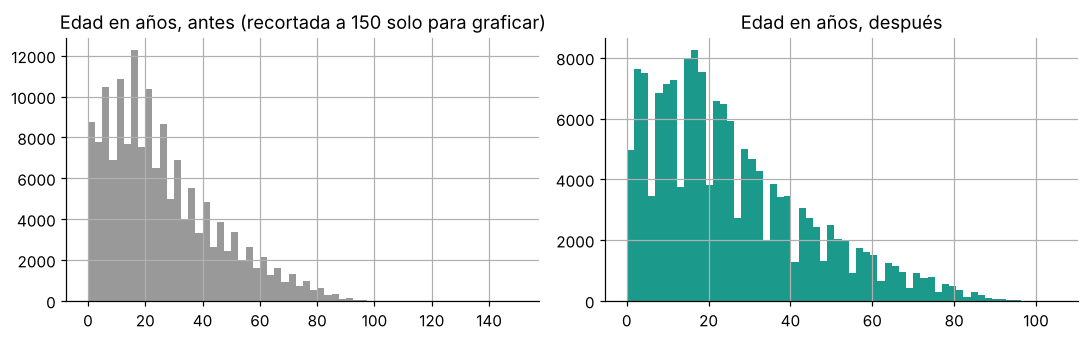

In [2]:
cases=pp.clean_cases(raw)
res=pd.DataFrame({
 "antes (nulos)":raw.isnull().sum(),
}).join(cases.isnull().sum().rename("después (nulos)"),how="outer").fillna("—")
display(res[res.index.isin(["localcod","localidad","diresa","edad"]) | res.index.isin(["edad_anios"])])
print("ubigeo con 5 dígitos antes:",(raw.ubigeo.astype(str).str.len()==5).sum()," | después:",(cases.ubigeo.str.len()!=6).sum())
print("edad > 110 años antes:",((raw.edad*raw.tipo_edad.map({"A":1,"M":1/12,"D":1/365}))>110).sum()," | después:",(cases.edad_anios>110).sum())
print("filas:",len(raw),"->",len(cases),"(los duplicados se conservan)")
print("columnas eliminadas:",sorted(set(raw.columns)-set(cases.columns)))
fig,ax=plt.subplots(1,2,figsize=(10,3.2))
(raw.edad*raw.tipo_edad.map({"A":1,"M":1/12,"D":1/365})).clip(upper=150).hist(bins=60,ax=ax[0],color="#999"); ax[0].set_title("Edad en años, antes (recortada a 150 solo para graficar)")
cases.edad_anios.hist(bins=60,ax=ax[1],color="#1B998B"); ax[1].set_title("Edad en años, después")
plt.tight_layout()

## 2. `build_monthly_panel`: estructura y control de fuga

In [3]:
panel=pp.build_monthly_panel(cases)
tr,te=pp.split_train_test(panel)
print(f"panel {panel.shape} | distritos {panel.ubigeo.nunique()} | {panel.fecha_mes.min():%Y-%m} a {panel.fecha_mes.max():%Y-%m}")
print("nulos en FEATURES:",int(panel[pp.FEATURES].isnull().sum().sum()))
print(f"train {len(tr):,} (hasta {tr.fecha_mes.max():%Y-%m}) | test {len(te):,} (desde {te.fecha_mes.min():%Y-%m})")
assert tr.fecha_mes.max()<te.fecha_mes.min(), "train y test se solapan"
# Control de fuga: lag1 de cada fila debe ser los casos del mes anterior del mismo distrito
chk=panel.sort_values(["ubigeo","fecha_mes"]).copy()
chk["casos_prev"]=chk.groupby("ubigeo")["casos"].shift(1)
ok=(chk.dropna(subset=["casos_prev"]).eval("lag1==casos_prev")).mean()
print(f"lag1 == casos del mes anterior: {ok:.1%} de las filas")
# lag12 y media3
chk["c12"]=chk.groupby("ubigeo")["casos"].shift(12)
print(f"lag12 correcto: {(chk.dropna(subset=['c12']).eval('lag12==c12')).mean():.1%}")
m3=chk.groupby("ubigeo")["casos"].transform(lambda s:s.shift(1).rolling(3).mean())
v=m3.notna()  # el panel ya no contiene los primeros meses, así que se compara donde se puede recalcular
print(f"media3 correcta: {np.isclose(chk.loc[v,'media3'],m3[v]).mean():.1%} (en {v.sum():,} filas comparables)")
panel.head()

panel (125280, 16) | distritos 435 | 2001-01 a 2024-12
nulos en FEATURES: 0
train 93,960 (hasta 2018-12) | test 31,320 (desde 2019-01)
lag1 == casos del mes anterior: 100.0% de las filas
lag12 correcto: 100.0%


media3 correcta: 100.0% (en 123,975 filas comparables)


,ubigeo,departamento,provincia,distrito,fecha_mes,es_train,casos,umbral,alerta,lag1,lag2,lag3,lag12,media3,mes_sin,mes_cos
0,010101,AMAZONAS,CHACHAPOYAS,CHACHAPOYAS,2001-01-01,True,3,5.214622,0,0.0,0.0,2.0,0.0,0.666667,0.500000,8.660254e-01
1,010101,AMAZONAS,CHACHAPOYAS,CHACHAPOYAS,2001-02-01,True,3,5.214622,0,3.0,0.0,0.0,0.0,1.000000,0.866025,5.000000e-01
2,010101,AMAZONAS,CHACHAPOYAS,CHACHAPOYAS,2001-03-01,True,1,5.214622,0,3.0,3.0,0.0,1.0,2.000000,1.000000,6.123234e-17
3,010101,AMAZONAS,CHACHAPOYAS,CHACHAPOYAS,2001-04-01,True,4,5.214622,0,1.0,3.0,3.0,0.0,2.333333,0.866025,-5.000000e-01
4,010101,AMAZONAS,CHACHAPOYAS,CHACHAPOYAS,2001-05-01,True,1,5.214622,0,4.0,1.0,3.0,0.0,2.666667,0.500000,-8.660254e-01


## 3. Serie de un distrito, alerta y partición

alerta train: 4.67%  |  test: 3.43%


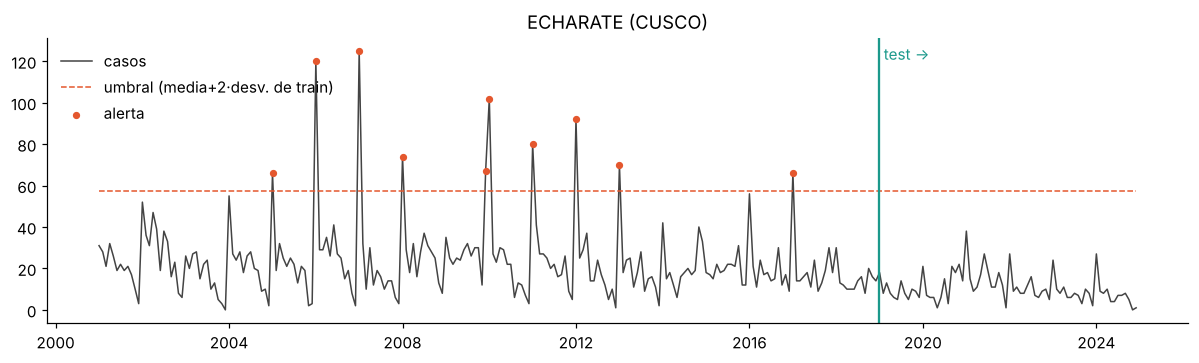

In [4]:
top=panel.groupby("ubigeo").casos.sum().idxmax()
d=panel[panel.ubigeo==top]
fig,ax=plt.subplots(figsize=(11,3.4))
ax.plot(d.fecha_mes,d.casos,color="#444",lw=1,label="casos")
ax.plot(d.fecha_mes,d.umbral,color="#E4572E",ls="--",lw=1,label="umbral (media+2·desv. de train)")
a=d[d.alerta==1]; ax.scatter(a.fecha_mes,a.casos,color="#E4572E",s=14,zorder=3,label="alerta")
ax.axvline(pd.Timestamp(pp.TRAIN_END),color="#1B998B"); ax.text(pd.Timestamp(pp.TRAIN_END),ax.get_ylim()[1]*0.92," test →",color="#1B998B")
ax.set_title(f"{d.distrito.iloc[0]} ({d.departamento.iloc[0]})"); ax.legend(frameon=False,loc="upper left"); plt.tight_layout()
print("alerta train: %.2f%%  |  test: %.2f%%"%(tr.alerta.mean()*100,te.alerta.mean()*100))

## 4. Escaladores: ajustados solo con train

,escalador,media train,desv. train,min train,max train,max test,NaN
0,none,1.245,3.149,0.000,125.000,68.000,0
1,standard,-0.000,1.000,-0.395,39.299,21.198,0
2,minmax,0.010,0.025,0.000,1.000,0.544,0
3,log1p_standard,0.000,1.000,-0.696,6.364,5.485,0


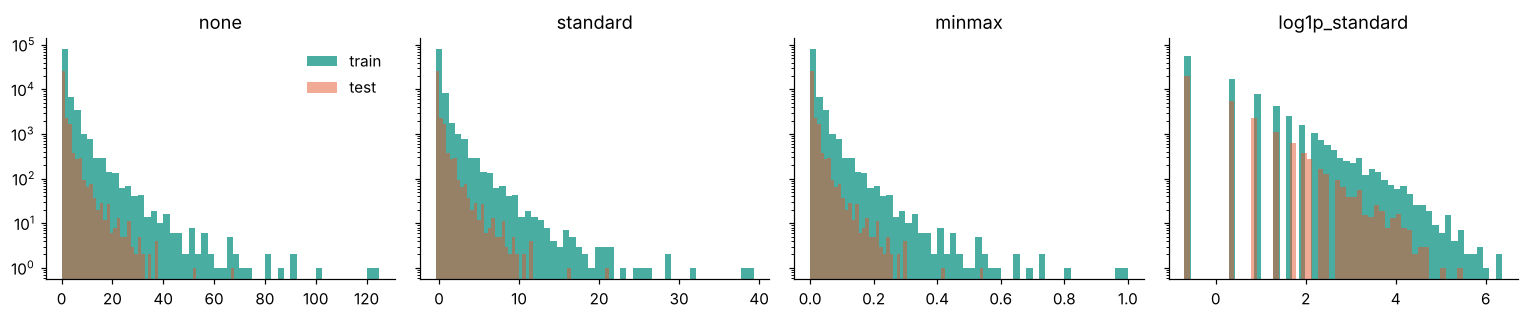

In [5]:
fig,axes=plt.subplots(1,4,figsize=(14,3),sharey=True)
filas=[]
for ax,k in zip(axes,["none","standard","minmax","log1p_standard"]):
    Xtr,Xte,sc=pp.scale_features(tr,te,k)
    ax.hist(Xtr["lag1"],bins=50,color="#1B998B",alpha=.8,label="train"); ax.hist(Xte["lag1"],bins=50,color="#E4572E",alpha=.5,label="test")
    ax.set_yscale("log"); ax.set_title(k)
    filas.append({"escalador":k,"media train":Xtr.lag1.mean(),"desv. train":Xtr.lag1.std(),"min train":Xtr.lag1.min(),"max train":Xtr.lag1.max(),"max test":Xte.lag1.max(),"NaN":int(Xte.isna().sum().sum())})
axes[0].legend(frameon=False); plt.tight_layout()
pd.DataFrame(filas).round(3)

In [6]:
# Comprobación de que el escalador NO vio el test: sus parámetros salen solo de train
Xtr,Xte,sc=pp.scale_features(tr,te,"standard")
print("media aprendida == media de train:",np.allclose(sc.mean_,tr[pp.FEATURES].mean()))
print("media aprendida == media de train+test:",np.allclose(sc.mean_,pd.concat([tr,te])[pp.FEATURES].mean()))
Xtr2,_,sc2=pp.scale_features(tr,te,"log1p_standard")
print("log1p_standard: mes_sin/mes_cos sin log1p (máx train = máx original):",np.isclose(Xtr2.mes_sin.max()*tr.mes_sin.std()+tr.mes_sin.mean(),tr.mes_sin.max()))

media aprendida == media de train: True
media aprendida == media de train+test: False
log1p_standard: mes_sin/mes_cos sin log1p (máx train = máx original): True


## 5. Pesos de clase y SMOTE

pesos: {0: 0.52, 1: 10.7}


peso*conteo por clase (debe ser ~igual): {0: 46980, 1: 46980}
filas: 93960 -> 179140 | test sin tocar: 31320


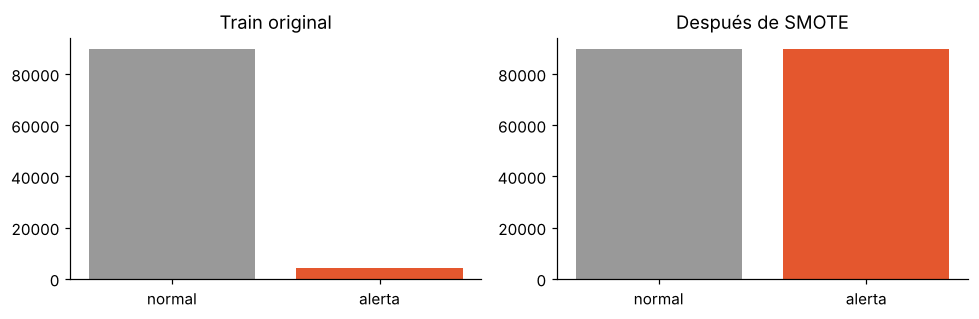

In [7]:
y=tr.alerta; w=pp.class_weights(y); print("pesos:",{k:round(v,2) for k,v in w.items()})
Xtr,_,_=pp.scale_features(tr,te,"log1p_standard")
Xs,ys=pp.apply_smote(Xtr,y)
fig,ax=plt.subplots(1,2,figsize=(9,3))
ax[0].bar(["normal","alerta"],y.value_counts().sort_index(),color=["#999","#E4572E"]); ax[0].set_title("Train original")
ax[1].bar(["normal","alerta"],ys.value_counts().sort_index(),color=["#999","#E4572E"]); ax[1].set_title("Después de SMOTE")
plt.tight_layout()
print("peso*conteo por clase (debe ser ~igual):",{c:round(w[c]*(y==c).sum()) for c in w})
print("filas:",len(y),"->",len(ys),"| test sin tocar:",len(te))

## 6. Sensibilidad sin la semana 1

casos en el panel: 144818 -> 135656
alertas en enero: 22.4% -> 11.4%
filas iguales: True


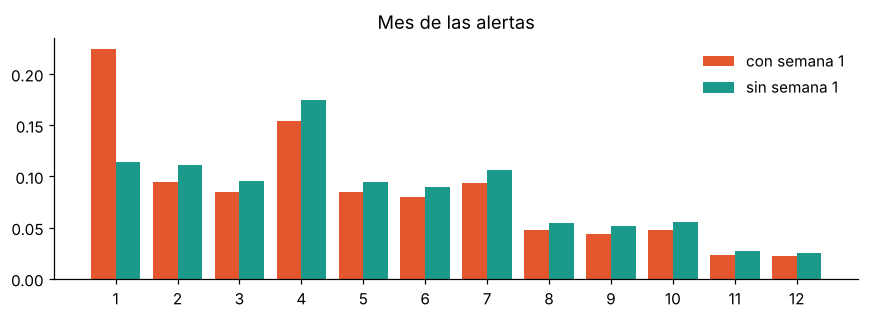

In [8]:
p1=pp.build_monthly_panel(cases,exclude_week1=True)
mes=lambda p:p[p.alerta==1].fecha_mes.dt.month.value_counts(normalize=True).sort_index()
fig,ax=plt.subplots(figsize=(8,3))
x=np.arange(1,13); ax.bar(x-.2,mes(panel).reindex(x,fill_value=0),.4,label="con semana 1",color="#E4572E"); ax.bar(x+.2,mes(p1).reindex(x,fill_value=0),.4,label="sin semana 1",color="#1B998B")
ax.set_xticks(x); ax.set_title("Mes de las alertas"); ax.legend(frameon=False); plt.tight_layout()
print("casos en el panel:",int(panel.casos.sum()),"->",int(p1.casos.sum()))
print("alertas en enero: %.1f%% -> %.1f%%"%(mes(panel).get(1,0)*100,mes(p1).get(1,0)*100))
print("filas iguales:",len(panel)==len(p1))

## 7. Reproducibilidad: `run()` guarda lo mismo

In [9]:
import tempfile, pathlib
with tempfile.TemporaryDirectory() as t:
    r=pp.run(RAW,t); back=pd.read_csv(pathlib.Path(t)/"panel_mensual_distrital.csv",dtype={"ubigeo":str})
    print("archivos:",sorted(p.name for p in pathlib.Path(t).iterdir()))
    print("panel guardado:",back.shape,"| igual al calculado:",back.shape==r["panel"].shape and np.allclose(back[pp.FEATURES].values,r["panel"][pp.FEATURES].values))

archivos: ['casos_limpios.csv', 'panel_mensual_distrital.csv']
panel guardado: (125280, 16) | igual al calculado: True
